# Modelagem baseline: volatilidade, direção e a combinação das duas

**Semana de 22/10.** Testamos fora da amostra a proposta do projeto:

> **dados estruturados → volatilidade** (quanto o BTC vai oscilar) e **notícias do GDELT → direção** (para onde).

Três perguntas:
1. A volatilidade do BTC é previsível? Mercado/macro e notícias ajudam além do próprio histórico do BTC?
2. A direção do dia seguinte é previsível? As notícias ajudam (ablação com e sem as features de notícias)?
3. Uma estratégia que usa a direção para decidir **se** entra e a volatilidade para decidir **quanto** entra supera o
   buy & hold depois dos custos?

Toda a validação é **walk-forward** (detalhes abaixo), sem nenhum dado do futuro no treino.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

DATA = Path.cwd().parent / "data"
ALPHA = 0.05

# Mesma paleta e tema do struc_data.ipynb
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GRAY = "#8a8985"
CMAP_DIV = sns.diverging_palette(250, 15, s=75, l=50, center="light", as_cmap=True)
sns.set_theme(style="whitegrid", rc={
    "axes.prop_cycle": plt.cycler(color=C), "axes.edgecolor": "#d6d5d0", "grid.color": "#ecebe7",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

def veredito(p, h0):
    print(f"   H0: {h0}")
    print(f"   p-valor = {p:.4g} -> {'REJEITA' if p < ALPHA else 'NÃO rejeita'} H0 (α = {ALPHA})")

In [2]:
from modeling.features import build_dataset, TAU_DEFAULT
from modeling import models as M

df = pd.read_csv(DATA / "integrated_dataframe.csv", index_col="Date", parse_dates=True)
N_CLUSTERS = int(pd.read_csv(DATA / "news_clusters.csv")["cluster"].max())
data, groups = build_dataset(df, N_CLUSTERS)
print(f"Base: {data.index.min().date()} a {data.index.max().date()} | {data.shape}")
display(pd.Series({g: len(c) for g, c in groups.items()}, name="nº de features").to_frame())

Base: 2017-02-01 a 2025-12-31 | (3256, 136)


,nº de features
btc,17
mercado_macro,60
noticias,44
mercado_vol,6
noticias_atencao,4


## 1. Alvos e validação

| Alvo | Definição | Uso |
|---|---|---|
| `target_logvol_7d` | log da volatilidade realizada dos **próximos 7 dias** (t+1 a t+7) | regressão de volatilidade |
| `target_up` | 1 se o retorno de t+1 > 0 | direção binária (AUC) |
| `target_class` | +1 (compra) se R(t+1) > τ, −1 (venda) se < −τ, 0 (manter) caso contrário | classificador da proposta original |

**τ = 0,30%:** custo de uma operação de ida e volta = 2 × (0,10% de taxa de corretora + 0,05% de slippage). Abaixo
disso, o movimento não paga o custo de operar, então a classe "manter" é a decisão correta.

**Walk-forward com janela expansiva:** para cada ano de teste (2020 a 2025), o modelo é treinado com **todos os dados
anteriores** a esse ano e testado nele. Há um **embargo de 7 dias** entre treino e teste, porque o alvo de volatilidade
olha 7 dias à frente: sem embargo, os últimos alvos do treino "veriam" os primeiros dias do teste. São 6 anos de teste
(≈ 2.190 dias) com regimes bem diferentes: pandemia (2020), bolha (2021), inverno cripto (2022), ETFs (2024).

In [3]:
dist = pd.DataFrame({f"τ = {t:.1%}": build_dataset(df, N_CLUSTERS, tau=t)[0]["target_class"].value_counts(normalize=True)
                     for t in [0.001, 0.003, 0.005, 0.01]}).rename(index={1.0: "compra (+1)", 0.0: "manter (0)", -1.0: "venda (−1)"})
display((dist * 100).round(1))
print(f"Dias de alta (target_up = 1): {data['target_up'].mean():.1%}")

,τ = 0.1%,τ = 0.3%,τ = 0.5%,τ = 1.0%
target_class,,,,
venda (−1),45.4000,41.2000,37.2000,29.1000
manter (0),4.4000,12.9000,21.0000,36.8000
compra (+1),50.2000,45.8000,41.9000,34.1000


Dias de alta (target_up = 1): 52.1%


## 2. Volatilidade

**Modelos comparados** (todos prevendo o log da volatilidade dos próximos 7 dias):

| Modelo | Ideia |
|---|---|
| média do treino | referência do R² fora da amostra (R²_oos = 0) |
| persistência | "a próxima semana vai ser como a última" |
| **HAR** (Corsi, 2009) | regressão sobre a volatilidade de 1, 7 e 30 dias; benchmark padrão da literatura |
| **GARCH(1,1)-t** | modelo clássico de clusters de volatilidade (sugerido em H3), reestimado a cada ano |
| HAR-X | HAR + variáveis exógenas, linear com regularização (Ridge) |
| LightGBM | mesmas entradas do HAR-X, modelo não linear |

**Conjuntos de variáveis exógenas:**
- `mercado_vol`: vol. de Parkinson e vol. negativa do BTC, volume anormal, vol. da Nasdaq e das bolsas globais, fim de semana;
- `atencao`: volume de notícias, volume anormal, % de notícias negativas, dispersão do tom;
- `completo`: **todas** as 120+ features (BTC, mercado, macro e notícias), para mostrar o efeito de usar tudo.

,rmse,r2_oos,corr
modelo,,,
media_treino,0.5740,0.0000,0.1590
persistencia,0.5850,-0.0380,0.4110
GARCH,0.5330,0.1380,0.4640
HAR,0.4870,0.2820,0.4580
HARX_mercado_vol,0.4820,0.2950,0.4730
HARX_atencao,0.4870,0.2800,0.4430
HARX_mercado_vol+atencao,0.4860,0.2850,0.4500
HARX_completo,1.0240,-2.1790,0.1560
LGBM_mercado_vol,0.5680,0.0210,0.2840


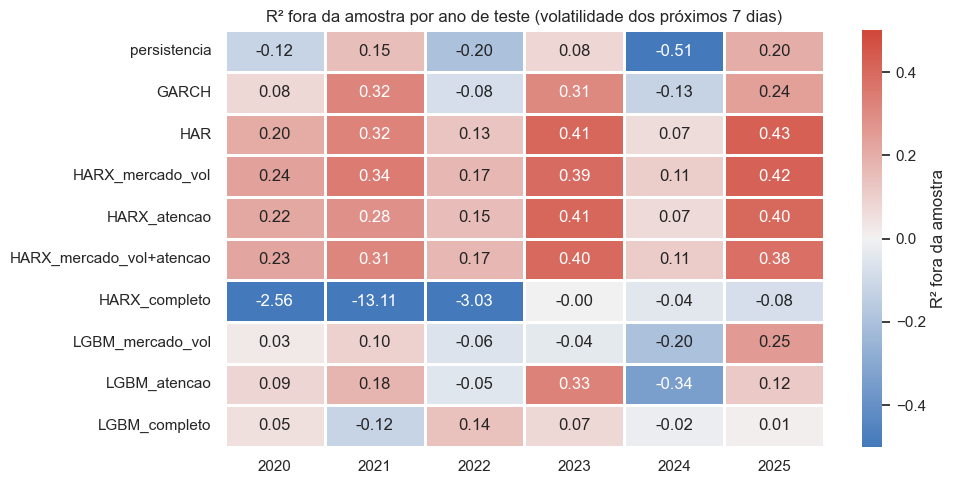

In [4]:
fs_vol = {
    "mercado_vol": groups["mercado_vol"],
    "atencao": groups["noticias_atencao"],
    "mercado_vol+atencao": groups["mercado_vol"] + groups["noticias_atencao"],
    "completo": groups["btc"] + groups["mercado_macro"] + groups["noticias"],
}
vp = M.volatility_walk_forward(data, fs_vol)
vp["GARCH"] = M.garch_forecast(np.log(df["BTC_Close"]).diff()).reindex(vp.index)
vp = vp.dropna()

geral, por_ano = M.volatility_metrics(vp)
ordem = ["media_treino", "persistencia", "GARCH", "HAR", "HARX_mercado_vol", "HARX_atencao", "HARX_mercado_vol+atencao",
         "HARX_completo", "LGBM_mercado_vol", "LGBM_atencao", "LGBM_completo"]
display(geral.loc[ordem].round(3))

r2 = por_ano.pivot(index="modelo", columns="ano", values="r2_oos").loc[ordem[1:]]
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(r2, cmap=CMAP_DIV, center=0, vmin=-0.5, vmax=0.5, annot=True, fmt=".2f", linewidths=1, linecolor="white",
            cbar_kws={"label": "R² fora da amostra"}, ax=ax)
ax.set_title("R² fora da amostra por ano de teste (volatilidade dos próximos 7 dias)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.show()

#### H14. As variáveis exógenas melhoram o HAR? (teste de Diebold-Mariano)

- **H0:** os dois modelos têm o mesmo erro quadrático esperado. Estatística negativa favorece o primeiro modelo.
- Variância de Newey-West com 6 defasagens, porque os alvos de 7 dias de dias vizinhos se sobrepõem.

In [5]:
pares = [("HARX_mercado_vol", "HAR"), ("HARX_atencao", "HAR"), ("HARX_mercado_vol+atencao", "HARX_mercado_vol"),
         ("HAR", "GARCH"), ("HAR", "LGBM_completo")]
dm = pd.DataFrame([{"modelo A": a, "modelo B": b, "DM": M.diebold_mariano(vp["real"], vp[a], vp[b])[0],
                    "p-valor": M.diebold_mariano(vp["real"], vp[a], vp[b])[1]} for a, b in pares])
dm["conclusão"] = np.where(dm["p-valor"] >= ALPHA, "sem diferença significativa",
                           np.where(dm["DM"] < 0, "A é melhor", "B é melhor"))
display(dm.round(4))

,modelo A,modelo B,DM,p-valor,conclusão
0,HARX_mercado_vol,HAR,-1.3298,0.1836,sem diferença significativa
1,HARX_atencao,HAR,0.2466,0.8052,sem diferença significativa
2,HARX_mercado_vol+atencao,HARX_mercado_vol,1.6223,0.1047,sem diferença significativa
3,HAR,GARCH,-6.4703,0.0000,A é melhor
4,HAR,LGBM_completo,-5.5573,0.0000,A é melhor


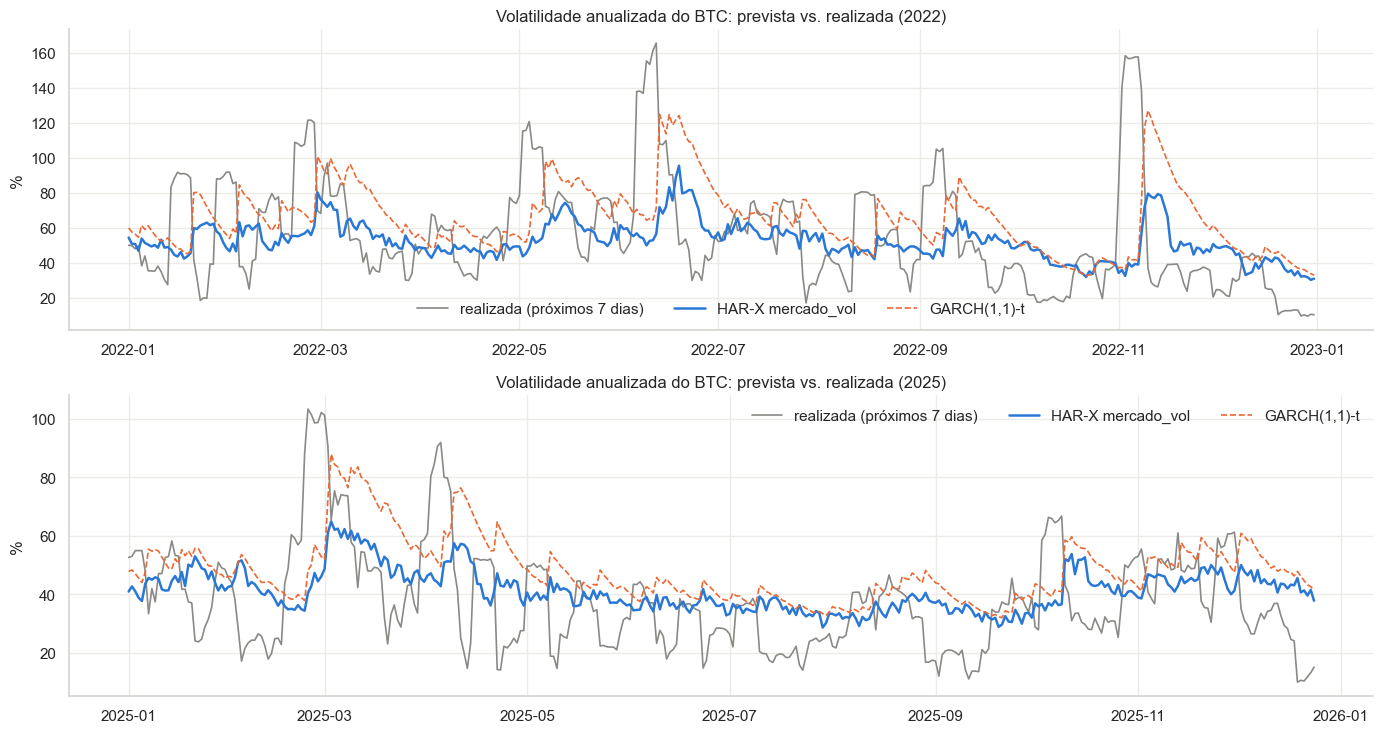

In [6]:
anual = lambda s: np.exp(s) * np.sqrt(365) * 100
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5))
for ax, ano in zip(axes, ["2022", "2025"]):
    p = vp.loc[ano]
    ax.plot(p.index, anual(p["real"]), color=GRAY, lw=1.2, label="realizada (próximos 7 dias)")
    ax.plot(p.index, anual(p["HARX_mercado_vol"]), color=C[0], lw=1.8, label="HAR-X mercado_vol")
    ax.plot(p.index, anual(p["GARCH"]), color=C[1], lw=1.2, ls="--", label="GARCH(1,1)-t")
    ax.set_title(f"Volatilidade anualizada do BTC: prevista vs. realizada ({ano})")
    ax.set_ylabel("%")
    ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

## 3. Direção do dia seguinte

**Conjuntos de features (ablação):**
- `btc`: só o histórico do próprio BTC (retornos, volatilidade, RSI, médias móveis, Bollinger, drawdown);
- `mercado`: `btc` + mercados globais, câmbio, juros e inflação (já sem vazamento);
- `noticias`: só as features do GDELT (tom, atenção, 11 clusters);
- `completo`: tudo.

**Modelos:** regressão logística (regularizada, balanceada) e LightGBM (raso e regularizado), mais a referência
"classe majoritária". Métrica principal: **AUC** (0,5 = moeda), com IC de 95% por **bootstrap em blocos de 30 dias**
(preserva a dependência temporal).

,acuracia_balanceada,f1_macro,auc,auc_ic95_inf,auc_ic95_sup
modelo,,,,,
maioria,0.5000,0.3380,0.5090,0.4900,0.5290
logit_btc,0.5070,0.5070,0.5090,0.4870,0.5340
LGBM_btc,0.5170,0.5170,0.5220,0.5020,0.5420
logit_mercado,0.5120,0.5100,0.5140,0.4920,0.5350
LGBM_mercado,0.5220,0.5180,0.5280,0.5050,0.5490
logit_noticias,0.5020,0.5010,0.5020,0.4780,0.5240
LGBM_noticias,0.4870,0.4860,0.4750,0.4530,0.4970
logit_completo,0.5080,0.5050,0.5120,0.4910,0.5340
LGBM_completo,0.5040,0.5030,0.5100,0.4850,0.5350


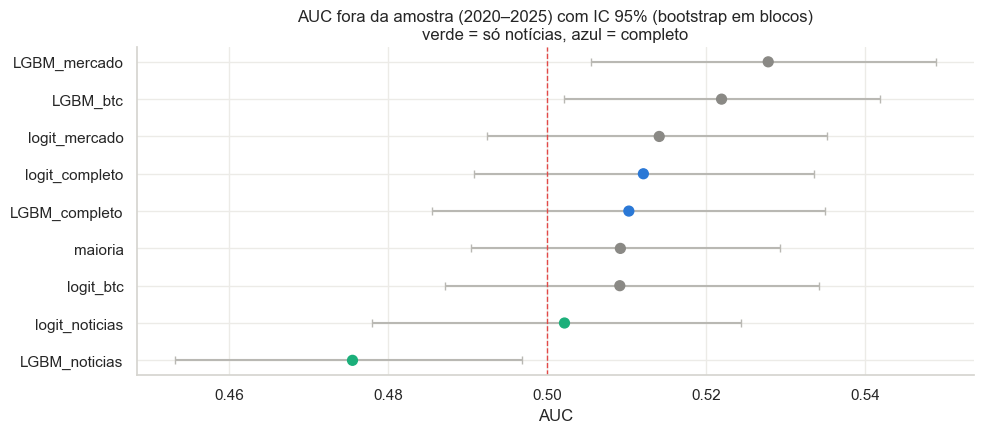

In [7]:
fs_dir = {
    "btc": groups["btc"],
    "mercado": groups["btc"] + groups["mercado_macro"],
    "noticias": groups["noticias"],
    "completo": groups["btc"] + groups["mercado_macro"] + groups["noticias"],
}
dp = M.direction_walk_forward(data, fs_dir, "target_up").dropna(subset=["logit_btc_pred"])
met = M.direction_metrics(dp)
display(met.round(3))

m = met.dropna(subset=["auc"]).sort_values("auc")
fig, ax = plt.subplots(figsize=(10, 4.5))
cores = [C[2] if "noticias" in i else C[0] if "completo" in i else GRAY for i in m.index]
ax.errorbar(m["auc"], range(len(m)), xerr=[m["auc"] - m["auc_ic95_inf"], m["auc_ic95_sup"] - m["auc"]],
            fmt="none", ecolor="#b9b8b3", capsize=3)
ax.scatter(m["auc"], range(len(m)), color=cores, s=50, zorder=3)
ax.set_yticks(range(len(m)), m.index)
ax.axvline(0.5, color=C[7], ls="--", lw=1)
ax.set_title("AUC fora da amostra (2020–2025) com IC 95% (bootstrap em blocos)\nverde = só notícias, azul = completo")
ax.set_xlabel("AUC")
plt.tight_layout()
plt.show()

#### H15. Adicionar as notícias melhora o modelo de direção?

Comparação pareada nos mesmos dias: AUC do modelo `completo` menos a AUC do modelo `mercado` (mesmo algoritmo), com IC
por bootstrap em blocos.

In [8]:
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(42)
y = dp["real"].values
linhas = []
for algo in ["logit", "LGBM"]:
    a, b = dp[f"{algo}_completo_proba"].values, dp[f"{algo}_mercado_proba"].values
    delta = roc_auc_score(y, a) - roc_auc_score(y, b)
    boots = []
    for _ in range(1000):
        starts = rng.integers(0, len(y) - 30, len(y) // 30)
        idx = np.concatenate([np.arange(s, s + 30) for s in starts])
        boots.append(roc_auc_score(y[idx], a[idx]) - roc_auc_score(y[idx], b[idx]))
    linhas.append({"algoritmo": algo, "ΔAUC (completo − mercado)": delta,
                   "IC95 inf": np.percentile(boots, 2.5), "IC95 sup": np.percentile(boots, 97.5)})
display(pd.DataFrame(linhas).set_index("algoritmo").round(4))

,ΔAUC (completo − mercado),IC95 inf,IC95 sup
algoritmo,,,
logit,-0.0020,-0.0218,0.0155
LGBM,-0.0175,-0.0344,0.0007


#### Classificador de 3 classes (compra / manter / venda) para diferentes τ

In [9]:
linhas = []
for tau in [0.001, 0.003, 0.005, 0.01]:
    d_tau = build_dataset(df, N_CLUSTERS, tau=tau)[0]
    pc = M.direction_walk_forward(d_tau, {"mercado": fs_dir["mercado"], "completo": fs_dir["completo"]},
                                  "target_class").dropna(subset=["logit_mercado_pred"])
    mt = M.direction_metrics(pc)
    for mod, row in mt.iterrows():
        linhas.append({"τ": f"{tau:.1%}", "modelo": mod, "acurácia balanceada": row["acuracia_balanceada"],
                       "F1 macro": row["f1_macro"]})
tab3 = pd.DataFrame(linhas).pivot(index="modelo", columns="τ", values="acurácia balanceada")
display(tab3.round(3))
print("Referência: acurácia balanceada de um classificador aleatório com 3 classes = 0,333")

τ,0.1%,0.3%,0.5%,1.0%
modelo,,,,
LGBM_completo,0.3400,0.3730,0.3650,0.3790
LGBM_mercado,0.3830,0.3720,0.3830,0.3930
logit_completo,0.3320,0.3690,0.3480,0.3520
logit_mercado,0.3400,0.3690,0.3510,0.3410
maioria,0.3330,0.3330,0.3330,0.3470


Referência: acurácia balanceada de um classificador aleatório com 3 classes = 0,333


,importância total (ganho)
BTC,0.1870
mercado/macro,0.4280
notícias,0.3860


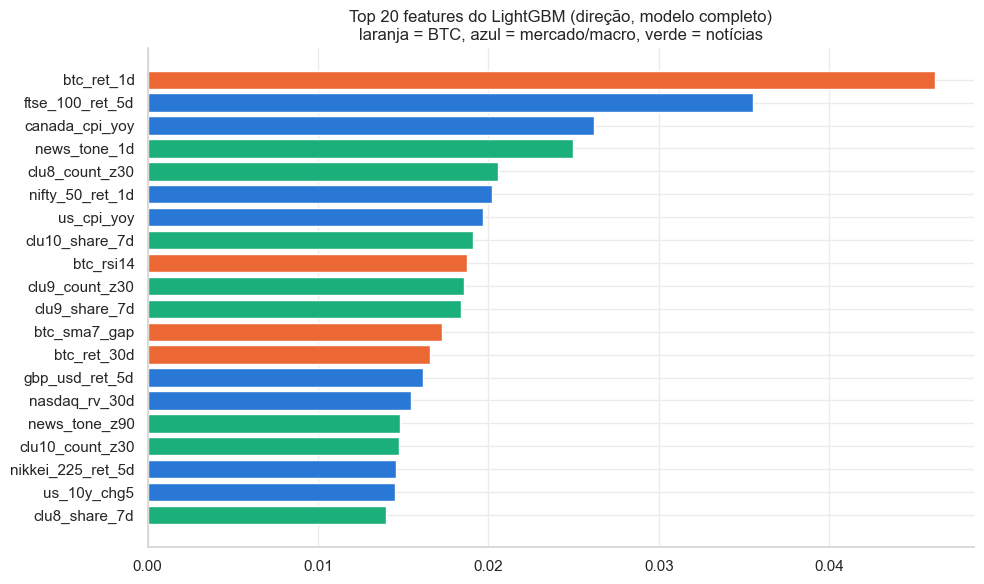

In [10]:
imp = M.feature_importance(data, fs_dir["completo"], "target_up", top=20)
grupo = lambda c: "notícias" if c.startswith(("news_", "clu")) else "BTC" if c.startswith("btc_") else "mercado/macro"
todas = M.feature_importance(data, fs_dir["completo"], "target_up", top=len(fs_dir["completo"]))
display(todas.groupby(todas.index.map(grupo)).sum().rename("importância total (ganho)").to_frame().round(3))

fig, ax = plt.subplots(figsize=(10, 6))
cores = {"notícias": C[2], "BTC": C[1], "mercado/macro": C[0]}
ax.barh(imp.index[::-1], imp.values[::-1], color=[cores[grupo(c)] for c in imp.index[::-1]])
ax.set_title("Top 20 features do LightGBM (direção, modelo completo)\nlaranja = BTC, azul = mercado/macro, verde = notícias")
plt.tight_layout()
plt.show()

**Atenção:** importância de feature mostra o que o modelo **usou** para se ajustar ao treino, e não o que **funciona**
fora da amostra. Com AUC ≈ 0,5, uma importância alta indica principalmente onde o modelo encontrou ruído para ajustar.

## 4. Backtest: direção × volatilidade

Estratégias long/flat (compra ou fica fora, sem venda a descoberto), decididas no fechamento de *t* e aplicadas ao
retorno de *t+1*, de 2020 a 2025, com custo de **0,15% por unidade negociada** (taxa + slippage de um lado):

| Estratégia | Posição |
|---|---|
| Buy & hold | 100% sempre |
| Alvo de volatilidade (HAR-X) | min(1, 50% ÷ vol. anualizada prevista): reduz a posição quando a volatilidade prevista sobe |
| Direção (mercado) | 100% se P(alta) do LightGBM `mercado` > 0,5, senão 0 |
| Direção (completo, com notícias) | idem, com o modelo `completo` |
| Direção (com notícias) + alvo de vol. | a combinação proposta pelo projeto |

Os resultados são **descritivos**: 6 anos de um único ativo é pouco para afirmar superioridade estatística de uma
estratégia, e a referência (buy & hold) teve um período excepcional.

,CAGR_%,vol_anual_%,sharpe,max_drawdown_%,retorno_total_%,exposição média %,trocas de posição por ano
Buy & hold,51.6600,61.0400,0.9900,-76.6300,"1,109.6900",100.0000,0.0000
Alvo de volatilidade (HAR-X),40.4700,53.6000,0.9100,-74.1900,664.6400,92.5000,NaN
Direção (mercado),-7.2800,44.1900,0.0600,-80.3900,-36.4000,41.2800,124.6700
"Direção (mercado), sem custos",11.8500,44.1600,0.4800,-67.7400,95.5400,41.2800,124.6700
"Direção (completo, com notícias)",-12.8300,45.0400,-0.0700,-84.2100,-56.0300,46.1800,133.6700
Direção (completo) + alvo de vol.,-15.7500,40.0900,-0.2200,-82.7800,-64.1500,42.7300,NaN


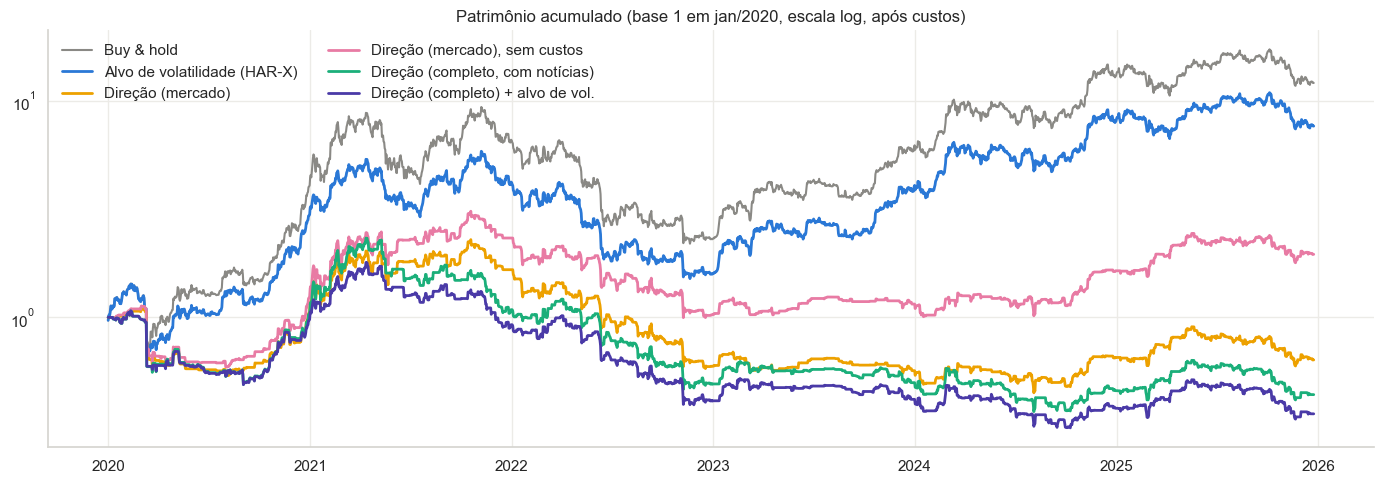

In [11]:
idx = vp.index.intersection(dp.index)
ret_next = np.expm1(data.loc[idx, "target_ret_1d"])
vol_anual = np.exp(vp.loc[idx, "HARX_mercado_vol"]) * np.sqrt(365)
VOL_ALVO = 0.50
tamanho = (VOL_ALVO / vol_anual).clip(upper=1)

sinal_merc = (dp.loc[idx, "LGBM_mercado_proba"] > 0.5).astype(float)
sinal_comp = (dp.loc[idx, "LGBM_completo_proba"] > 0.5).astype(float)
um = pd.Series(1.0, index=idx)

estrategias = {
    "Buy & hold": M.backtest(ret_next, um),
    "Alvo de volatilidade (HAR-X)": M.backtest(ret_next, um, tamanho),
    "Direção (mercado)": M.backtest(ret_next, sinal_merc),
    "Direção (mercado), sem custos": M.backtest(ret_next, sinal_merc, cost=0.0),
    "Direção (completo, com notícias)": M.backtest(ret_next, sinal_comp),
    "Direção (completo) + alvo de vol.": M.backtest(ret_next, sinal_comp, tamanho),
}
perf = pd.DataFrame({k: M.performance(v) for k, v in estrategias.items()}).T
perf["exposição média %"] = [100.0, tamanho.mean() * 100, sinal_merc.mean() * 100, sinal_merc.mean() * 100,
                              sinal_comp.mean() * 100, (sinal_comp * tamanho).mean() * 100]
perf["trocas de posição por ano"] = [0, np.nan] + [s.diff().abs().gt(0).sum() / 6 for s in [sinal_merc, sinal_merc, sinal_comp]] + [np.nan]
display(perf.round(2))

fig, ax = plt.subplots(figsize=(14, 5))
for (nome, pnl), cor in zip(estrategias.items(), [GRAY, C[0], C[3], C[4], C[2], C[6]]):
    ax.plot((1 + pnl).cumprod(), label=nome, color=cor, lw=2 if nome != "Buy & hold" else 1.5)
ax.set_yscale("log")
ax.set_title("Patrimônio acumulado (base 1 em jan/2020, escala log, após custos)")
ax.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.show()

## 5. Conclusões

**Volatilidade: previsível, e o histórico do próprio BTC é o que importa**
1. O **HAR** prevê a volatilidade dos próximos 7 dias com **R² fora da amostra ≈ 0,28**, positivo em todos os 6 anos de
   teste. É significativamente melhor que o GARCH(1,1)-t (Diebold-Mariano, p < 0,001) e que o LightGBM com todas as
   features (p < 0,001).
2. **Usar tudo piora:** o HAR-X com as 120+ features chega a R² = −2,2, e o LightGBM completo, a 0,05. Com regimes tão
   diferentes entre os anos (juro zero → juro alto, varejo → ETFs), muitas variáveis viram sobreajuste. Modelos
   parcimoniosos generalizam melhor.
3. A **volatilidade de mercado** (Nasdaq, bolsas globais, amplitude intradiária) melhora um pouco o HAR (R² 0,295 vs.
   0,282, melhor em 4 dos 6 anos), mas **sem significância estatística** (DM p ≈ 0,18). A **atenção da mídia não acrescenta
   nada** (R² 0,280).

**Direção: praticamente imprevisível, e as notícias não ajudam**

4. O melhor modelo (LightGBM com BTC + mercado) tem **AUC ≈ 0,53**, com IC 95% de 0,505 a 0,549: acima de uma moeda,
   mas por muito pouco. No caso de 3 classes, a acurácia balanceada fica entre 0,37 e 0,39, contra 0,333 do acaso.
5. **Ablação das notícias:** o modelo só com notícias não supera a moeda (AUC 0,50 no logit; 0,48 no LightGBM, pior que
   a moeda, sinal de sobreajuste), e somar as notícias ao modelo de mercado **não melhora** a AUC (Δ = −0,002 e −0,018).
   Isso confirma fora da amostra o que o estudo de eventos mostrou: o tom diário do GDELT **reage** ao preço.
6. O LightGBM atribui ~39% da importância às notícias, mas isso é ajuste ao ruído do treino, que não se traduz em
   desempenho fora da amostra.

**Backtest (descritivo)**

7. Nenhuma estratégia supera o buy & hold em 2020–2025 (Sharpe ≈ 0,99). As estratégias de direção **perdem dinheiro**
   depois dos custos: trocam de posição cerca de 125 vezes por ano, e o pequeno poder preditivo não paga isso. Mesmo
   **sem custos**, a direção (mercado) rende ≈ 12% ao ano, contra ≈ 52% do buy & hold, porque fica fora do mercado em quase
   60% dos dias de um período de forte alta.
8. O **alvo de volatilidade** reduz a volatilidade da carteira (61% → 54%) com Sharpe parecido (0,91). Com alvo de 50%
   ao ano, a posição fica perto de 100% na maior parte do tempo; o efeito aparece só nos picos de volatilidade.

**Resposta à proposta do projeto**

| Proposta | Resultado |
|---|---|
| dados estruturados → volatilidade | ✅ confirmada (HAR R² ≈ 0,28; o histórico do BTC carrega quase toda a informação) |
| notícias (GDELT) → direção | ❌ não confirmada com notícias diárias: o tom reage ao preço e não adiciona poder preditivo |

**Próximos passos sugeridos**
- **Eventos agendados** (decisões do FOMC, divulgação do CPI, aprovação dos ETFs): o horário do evento é conhecido de
  antemão, então dá para medir a reação do preço e da volatilidade *depois* do evento, sem o problema de causalidade
  reversa das notícias espontâneas. É o uso clássico do estudo de eventos e combina com o nome do projeto.
- **GDELT intradiário** (resolução de 15 min): testar se a notícia antecede o preço em horas, o que a agregação diária
  esconde.
- **Volatilidade como produto principal:** prever **dias extremos** (|retorno| > 3σ) e regimes de estresse, que é a
  parte da proposta original sobre "padrões extremos" (RBM/BAM), agora sobre um alvo que se mostrou previsível.
- **Republicar a base no HuggingFace** com a defasagem de publicação.